Import libraries and load the dataset

In [4]:

# Step 1: Import Libraries and Load the AQI Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
file_path = "/content/city_day.csv"
df = pd.read_csv(file_path)

# Display basic dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display the first five rows
print("\nFirst five rows of the dataset:")
display(df.head())

# Display all column names
print("\nDataset columns:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()


Dataset loaded successfully!
Dataset shape: (29531, 16)

First five rows of the dataset:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Dataset columns:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  2485

Check missing values

In [5]:

# Step 2: Check Missing Values and Duplicate Records

# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing-value percentages
missing_percentage = (missing_count / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage.round(2)
})

# Display only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

print("Missing Values Summary:")
display(missing_summary)

# Count all missing cells
print("\nTotal missing cells:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())


Missing Values Summary:


,Missing Values,Missing Percentage (%)
Xylene,18109,61.32
PM10,11140,37.72
NH3,10328,34.97
Toluene,8041,27.23
Benzene,5623,19.04
AQI,4681,15.85
AQI_Bucket,4681,15.85
PM2.5,4598,15.57
NOx,4185,14.17
O3,4022,13.62



Total missing cells: 88488
Duplicate rows: 0


Clean the dataset

In [6]:

# Step 3: Clean the AQI Dataset

# Create a copy of the original dataset
df_clean = df.copy()

print("Original dataset shape:", df_clean.shape)

# Step 1: Remove rows where the target AQI is missing
df_clean = df_clean.dropna(subset=["AQI"]).copy()

# Step 2: Remove AQI_Bucket because AQI is our prediction target
# and AQI_Bucket is derived from AQI
df_clean = df_clean.drop(columns=["AQI_Bucket"])

# Step 3: Remove Xylene because it has a high percentage
# of missing values (61.32%)
df_clean = df_clean.drop(columns=["Xylene"])

# Step 4: Convert Date into a datetime format
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"], errors="coerce"
)

# Remove rows with invalid dates
df_clean = df_clean.dropna(subset=["Date"]).copy()

# Display the cleaned dataset information
print("\nDataset cleaning completed!")
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
display(
    df_clean.isnull().sum()
    .to_frame(name="Missing Values")
    .query("`Missing Values` > 0")
)

print("\nRemaining missing cells:", df_clean.isnull().sum().sum())

print("\nFirst five rows of the cleaned dataset:")
display(df_clean.head())


Original dataset shape: (29531, 16)

Dataset cleaning completed!
Cleaned dataset shape: (24850, 14)

Remaining missing values:


,Missing Values
PM2.5,678
PM10,7086
NO,387
NO2,391
NOx,1857
NH3,6536
CO,445
SO2,605
O3,807
Benzene,3535



Remaining missing cells: 28153

First five rows of the cleaned dataset:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI
28,Ahmedabad,2015-01-29,83.13,NaN,6.93,28.71,33.72,NaN,6.93,49.52,59.76,0.02,0.00,209.0
29,Ahmedabad,2015-01-30,79.84,NaN,13.85,28.68,41.08,NaN,13.85,48.49,97.07,0.04,0.00,328.0
30,Ahmedabad,2015-01-31,94.52,NaN,24.39,32.66,52.61,NaN,24.39,67.39,111.33,0.24,0.01,514.0
31,Ahmedabad,2015-02-01,135.99,NaN,43.48,42.08,84.57,NaN,43.48,75.23,102.70,0.40,0.04,782.0
32,Ahmedabad,2015-02-02,178.33,NaN,54.56,35.31,72.80,NaN,54.56,55.04,107.38,0.46,0.06,914.0


Prepare the features and split the data

In [7]:

# Step 4: Prepare Features and Split the Dataset

# Import required library
import pandas as pd

# Sort the dataset chronologically
df_clean = df_clean.sort_values("Date").reset_index(drop=True)

# Define the target variable
target = "AQI"

# Select input features
feature_cols = [
    "City",
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene",
    "Date"
]

# Create input features (X) and target (y)
X = df_clean[feature_cols].copy()
y = df_clean[target].copy()

# Extract date components as numerical features
X["Year"] = X["Date"].dt.year
X["Month"] = X["Date"].dt.month
X["Day"] = X["Date"].dt.day

# Remove the original Date column from the input features
X = X.drop(columns=["Date"])

# Split by unique dates to prevent the same date appearing
# in both training and testing datasets
unique_dates = sorted(df_clean["Date"].unique())

split_position = int(len(unique_dates) * 0.80)
split_date = unique_dates[split_position]

# Training data: dates before the split date
train_mask = df_clean["Date"] < split_date

# Testing data: dates on or after the split date
test_mask = df_clean["Date"] >= split_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

# Display the results
print("Feature preparation and data splitting completed!")

print("\nTotal records:", len(X))
print("Number of input features:", X.shape[1])

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining date range:")
print(
    df_clean.loc[train_mask, "Date"].min(),
    "to",
    df_clean.loc[train_mask, "Date"].max()
)

print("\nTesting date range:")
print(
    df_clean.loc[test_mask, "Date"].min(),
    "to",
    df_clean.loc[test_mask, "Date"].max()
)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)


Feature preparation and data splitting completed!

Total records: 24850
Number of input features: 15

Training records: 16018
Testing records: 8832

Training date range:
2015-01-01 00:00:00 to 2019-05-26 00:00:00

Testing date range:
2019-05-27 00:00:00 to 2020-07-01 00:00:00

Training feature shape: (16018, 15)
Testing feature shape: (8832, 15)


Build the preprocessing pipeline

In [8]:

# Step 5: Build the Preprocessing Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", categorical_features)

# Pipeline for numerical features
# Replace missing numerical values with the training-set median
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Pipeline for categorical features
# Replace missing categories with the most frequent value
# Convert city names into numerical indicator columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the numerical and categorical preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit preprocessing using training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted preprocessing to testing data
X_test_processed = preprocessor.transform(X_test)

# Display the results
print("\nPreprocessing completed successfully!")

print("Original training shape:", X_train.shape)
print("Original testing shape:", X_test.shape)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

# Verify that no missing values remain after preprocessing
print("\nMissing values in processed training data:",
      np.isnan(X_train_processed).sum())

print("Missing values in processed testing data:",
      np.isnan(X_test_processed).sum())


Numerical features: 14
Categorical features: ['City']

Preprocessing completed successfully!
Original training shape: (16018, 15)
Original testing shape: (8832, 15)
Processed training shape: (16018, 33)
Processed testing shape: (8832, 33)

Missing values in processed training data: 0
Missing values in processed testing data: 0


Install XGBoost

In [1]:

# Step 6.1: Install XGBoost

%pip install -q xgboost

print("XGBoost installation completed!")


XGBoost installation completed!


Train and evaluate all four models

In [9]:

# Step 6.2: Train and Evaluate Four Machine-Learning Models

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define the four models
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

# Store evaluation results and trained models
results = []
trained_models = {}

# Train and evaluate each model
for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    # Train the model
    model.fit(X_train_processed, y_train)

    # Predict AQI values for the test dataset
    y_pred = model.predict(X_test_processed)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Save the trained model
    trained_models[model_name] = model

    # Store the metrics
    results.append({
        "Model": model_name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2 Score": round(r2, 4)
    })

    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))

# Create the model comparison table
results_df = pd.DataFrame(results)

# Sort by RMSE: lowest error first
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("\nFinal AQI Model Comparison:")
display(results_df)

# Save the results to a CSV file
results_df.to_csv(
    "/content/aqi_model_performance_results.csv",
    index=False
)

print("\nResults saved to aqi_model_performance_results.csv")



Training Linear Regression...
MAE: 24.9152
RMSE: 37.3474
R2 Score: 0.8709

Training Random Forest...
MAE: 17.7693
RMSE: 32.3495
R2 Score: 0.9032

Training Gradient Boosting...
MAE: 18.4283
RMSE: 31.4081
R2 Score: 0.9087

Training XGBoost...
MAE: 17.7473
RMSE: 35.077
R2 Score: 0.8862

Final AQI Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Gradient Boosting,18.4283,31.4081,0.9087
1,Random Forest,17.7693,32.3495,0.9032
2,XGBoost,17.7473,35.0770,0.8862
3,Linear Regression,24.9152,37.3474,0.8709



Results saved to aqi_model_performance_results.csv


Visualize model performance

AQI PREDICTION: VISUALIZATION REPORT
Best model selected by lowest test RMSE: Gradient Boosting
Test MAE:  18.4283
Test RMSE: 31.4081
Test R2:   0.9087
Test samples: 8832
Output directory: /content/AQI_Research_Figures


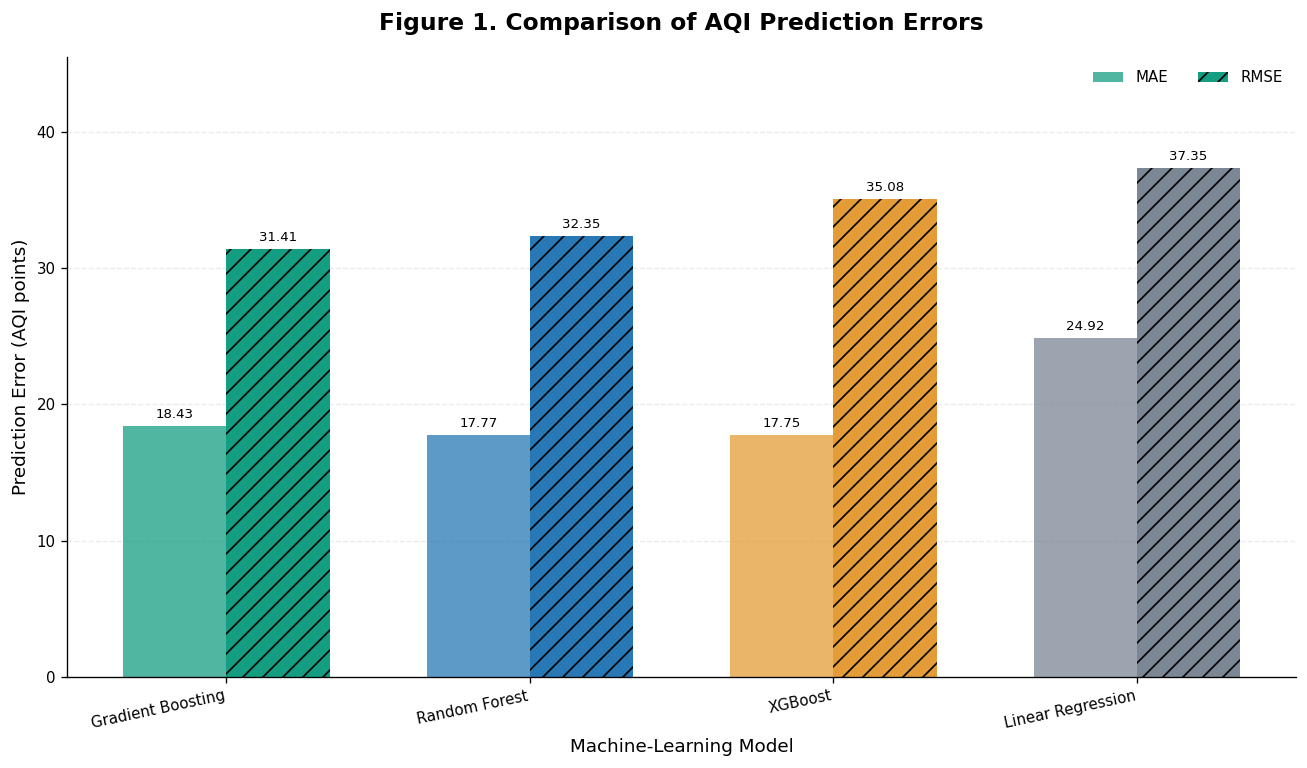

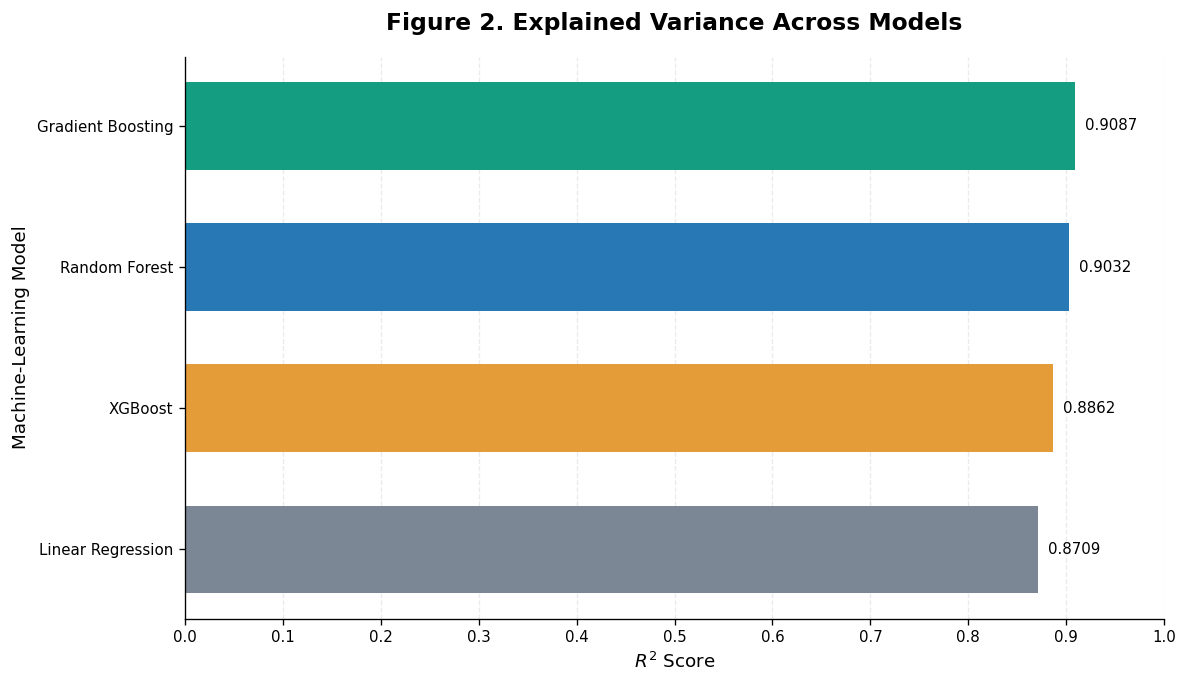

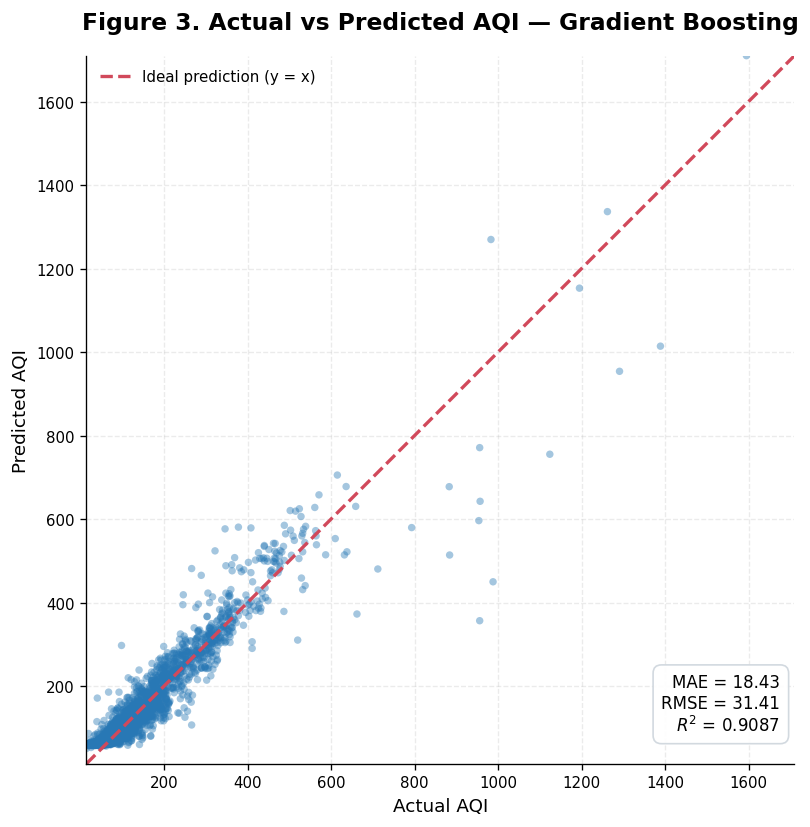

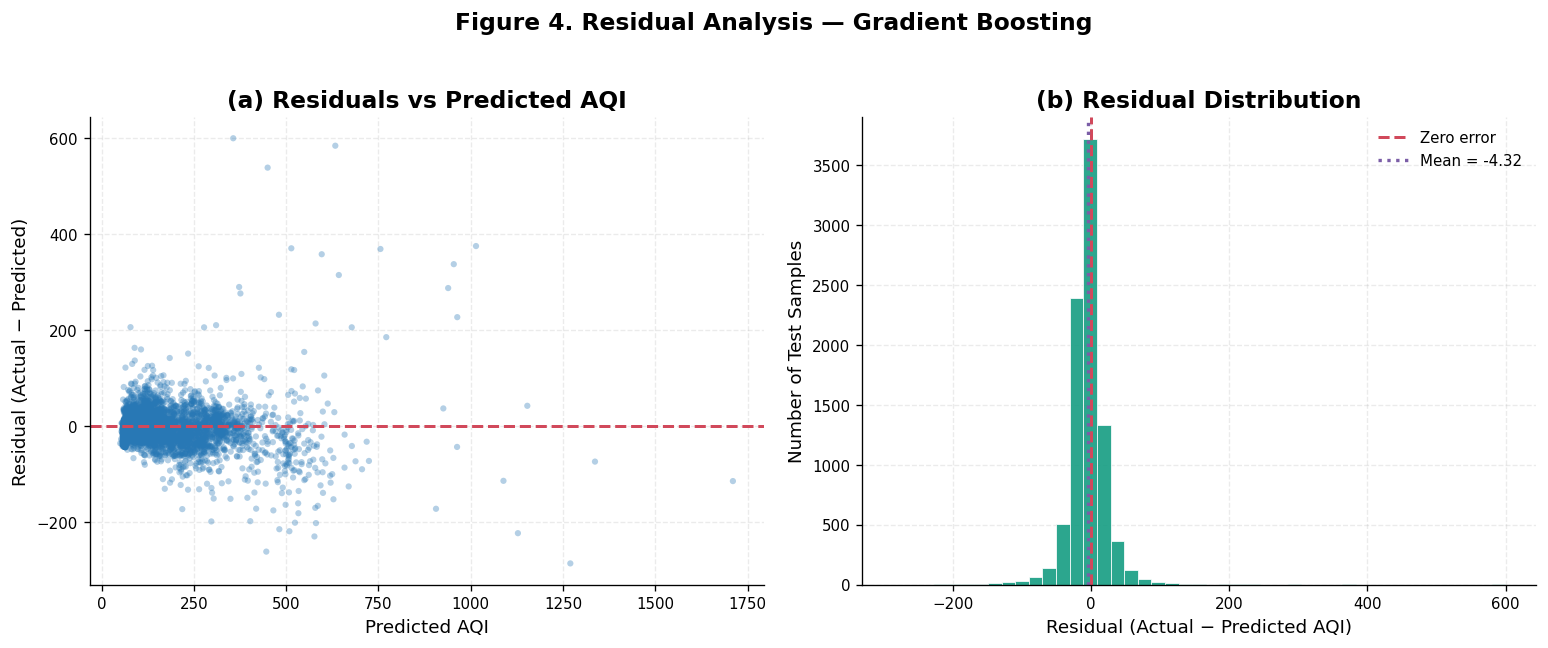

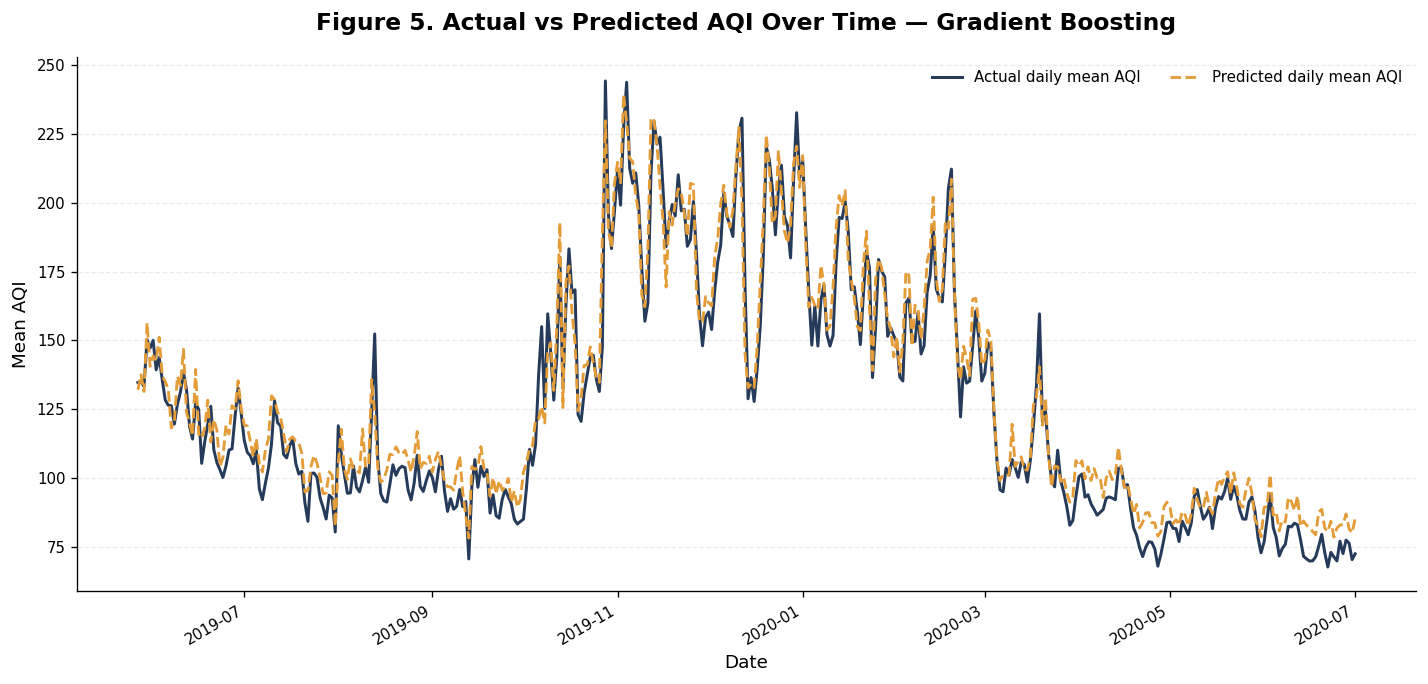


ALL VISUALIZATIONS GENERATED SUCCESSFULLY
Saved files:
 - figure_1_error_comparison.pdf
 - figure_1_error_comparison.png
 - figure_2_r2_comparison.pdf
 - figure_2_r2_comparison.png
 - figure_3_actual_vs_predicted.pdf
 - figure_3_actual_vs_predicted.png
 - figure_4_residual_analysis.pdf
 - figure_4_residual_analysis.png
 - figure_5_aqi_time_series.pdf
 - figure_5_aqi_time_series.png
 - model_performance_metrics.csv


In [10]:

# ================================================================
# STEP 7: PUBLICATION-QUALITY AQI MODEL VISUALIZATION
# Project: AQI Prediction Using Machine Learning
# Models: Linear Regression, Random Forest, Gradient Boosting, XGBoost
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------
# 1. CONFIGURATION AND VISUAL STYLE
# ------------------------------------------------

OUTPUT_DIR = "/content/AQI_Research_Figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Consistent publication-style typography and layout
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
    "savefig.bbox": "tight",
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

# Consistent colors for the four models
MODEL_COLORS = {
    "Linear Regression": "#7B8794",
    "Random Forest": "#2878B5",
    "Gradient Boosting": "#159D82",
    "XGBoost": "#E39C37"
}

# Verify required variables
required_variables = [
    "results_df", "trained_models",
    "X_test_processed", "y_test"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Run the earlier data preparation, preprocessing, "
        "and model-training cells first."
    )

# Standardize the results table
plot_df = results_df.copy()

required_columns = {"Model", "MAE", "RMSE", "R2 Score"}

if not required_columns.issubset(plot_df.columns):
    raise ValueError(
        "results_df must contain Model, MAE, RMSE, and R2 Score."
    )

plot_df = plot_df.sort_values("RMSE", ascending=True).reset_index(drop=True)

best_model_name = plot_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

# Generate fresh predictions from the selected model
y_actual = np.asarray(y_test).ravel()
y_pred_best = np.asarray(
    best_model.predict(X_test_processed)
).ravel()

residuals = y_actual - y_pred_best

# Recalculate metrics from the predictions used in the figures
best_mae = mean_absolute_error(y_actual, y_pred_best)
best_rmse = np.sqrt(mean_squared_error(y_actual, y_pred_best))
best_r2 = r2_score(y_actual, y_pred_best)

print("=" * 68)
print("AQI PREDICTION: VISUALIZATION REPORT")
print("=" * 68)
print("Best model selected by lowest test RMSE:", best_model_name)
print(f"Test MAE:  {best_mae:.4f}")
print(f"Test RMSE: {best_rmse:.4f}")
print(f"Test R2:   {best_r2:.4f}")
print("Test samples:", len(y_actual))
print("Output directory:", OUTPUT_DIR)


# ------------------------------------------------
# 2. FIGURE 1: MAE AND RMSE MODEL COMPARISON
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6.5))

x = np.arange(len(plot_df))
bar_width = 0.34

mae_bars = ax.bar(
    x - bar_width / 2,
    plot_df["MAE"],
    width=bar_width,
    color=[
        MODEL_COLORS.get(name, "#2878B5")
        for name in plot_df["Model"]
    ],
    alpha=0.75,
    label="MAE"
)

rmse_bars = ax.bar(
    x + bar_width / 2,
    plot_df["RMSE"],
    width=bar_width,
    color=[
        MODEL_COLORS.get(name, "#2878B5")
        for name in plot_df["Model"]
    ],
    alpha=1.0,
    hatch="//",
    label="RMSE"
)

ax.bar_label(mae_bars, fmt="%.2f", padding=3, fontsize=8)
ax.bar_label(rmse_bars, fmt="%.2f", padding=3, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=12, ha="right")
ax.set_ylabel("Prediction Error (AQI points)")
ax.set_xlabel("Machine-Learning Model")
ax.set_title("Figure 1. Comparison of AQI Prediction Errors", pad=16)
ax.legend(frameon=False, ncol=2, loc="upper right")
ax.set_ylim(0, plot_df[["MAE", "RMSE"]].to_numpy().max() * 1.22)
ax.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/figure_1_error_comparison.png")
fig.savefig(f"{OUTPUT_DIR}/figure_1_error_comparison.pdf")
plt.show()


# ------------------------------------------------
# 3. FIGURE 2: R-SQUARED MODEL COMPARISON
# ------------------------------------------------

r2_df = plot_df.sort_values("R2 Score", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5.8))

bars = ax.barh(
    r2_df["Model"],
    r2_df["R2 Score"],
    color=[
        MODEL_COLORS.get(name, "#2878B5")
        for name in r2_df["Model"]
    ],
    height=0.62
)

ax.bar_label(bars, fmt="%.4f", padding=6, fontsize=9)
ax.set_xlim(0, 1.0)
ax.set_xlabel(r"$R^2$ Score")
ax.set_ylabel("Machine-Learning Model")
ax.set_title("Figure 2. Explained Variance Across Models", pad=16)
ax.xaxis.set_major_locator(mticker.MultipleLocator(0.1))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/figure_2_r2_comparison.png")
fig.savefig(f"{OUTPUT_DIR}/figure_2_r2_comparison.pdf")
plt.show()


# ------------------------------------------------
# 4. FIGURE 3: ACTUAL VS PREDICTED AQI
# ------------------------------------------------

# Plot a reproducible sample if the test set is very large.
# All metrics above are still calculated using the full test set.
rng = np.random.default_rng(42)
sample_size = min(4000, len(y_actual))
sample_idx = rng.choice(
    len(y_actual), size=sample_size, replace=False
)

actual_sample = y_actual[sample_idx]
pred_sample = y_pred_best[sample_idx]

axis_min = min(actual_sample.min(), pred_sample.min())
axis_max = max(actual_sample.max(), pred_sample.max())

fig, ax = plt.subplots(figsize=(8.5, 7))

scatter = ax.scatter(
    actual_sample,
    pred_sample,
    s=20,
    alpha=0.42,
    color="#2878B5",
    edgecolors="none",
    rasterized=True
)

ax.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    linestyle="--",
    linewidth=2,
    color="#D1495B",
    label="Ideal prediction (y = x)"
)

ax.set_xlabel("Actual AQI")
ax.set_ylabel("Predicted AQI")
ax.set_title(
    f"Figure 3. Actual vs Predicted AQI — {best_model_name}",
    pad=16
)
ax.legend(frameon=False, loc="upper left")
ax.text(
    0.98, 0.04,
    f"MAE = {best_mae:.2f}\nRMSE = {best_rmse:.2f}\n"
    f"$R^2$ = {best_r2:.4f}",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white",
              edgecolor="#D0D7DE", alpha=0.95)
)

ax.set_xlim(axis_min, axis_max)
ax.set_ylim(axis_min, axis_max)
ax.set_aspect("equal", adjustable="box")

fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/figure_3_actual_vs_predicted.png")
fig.savefig(f"{OUTPUT_DIR}/figure_3_actual_vs_predicted.pdf")
plt.show()


# ------------------------------------------------
# 5. FIGURE 4: RESIDUAL DIAGNOSTICS
# ------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Panel A: Residuals versus predictions
axes[0].scatter(
    y_pred_best,
    residuals,
    s=14,
    alpha=0.35,
    color="#2878B5",
    edgecolors="none",
    rasterized=True
)

axes[0].axhline(
    0, color="#D1495B", linestyle="--", linewidth=1.8
)

axes[0].set_xlabel("Predicted AQI")
axes[0].set_ylabel("Residual (Actual − Predicted)")
axes[0].set_title("(a) Residuals vs Predicted AQI")

# Panel B: Distribution of residuals
axes[1].hist(
    residuals,
    bins=45,
    color="#159D82",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.9
)

axes[1].axvline(
    0, color="#D1495B", linestyle="--", linewidth=1.8,
    label="Zero error"
)

axes[1].axvline(
    np.mean(residuals), color="#7B5EA7", linestyle=":",
    linewidth=2, label=f"Mean = {np.mean(residuals):.2f}"
)

axes[1].set_xlabel("Residual (Actual − Predicted AQI)")
axes[1].set_ylabel("Number of Test Samples")
axes[1].set_title("(b) Residual Distribution")
axes[1].legend(frameon=False)

fig.suptitle(
    f"Figure 4. Residual Analysis — {best_model_name}",
    fontsize=14,
    fontweight="bold",
    y=1.03
)

fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/figure_4_residual_analysis.png")
fig.savefig(f"{OUTPUT_DIR}/figure_4_residual_analysis.pdf")
plt.show()


# ------------------------------------------------
# 6. FIGURE 5: ACTUAL AND PREDICTED AQI OVER TIME
# ------------------------------------------------

# Use original row indices to recover the test dates.
# This assumes X_test and y_test retain the original row indices.
test_dates = df_clean.loc[y_test.index, "Date"].to_numpy()

time_df = pd.DataFrame({
    "Date": pd.to_datetime(test_dates),
    "Actual AQI": y_actual,
    "Predicted AQI": y_pred_best
}).sort_values("Date")

# If multiple cities have observations on the same day,
# average their actual and predicted AQI for a readable daily trend.
daily_df = time_df.groupby("Date", as_index=False).agg({
    "Actual AQI": "mean",
    "Predicted AQI": "mean"
})

fig, ax = plt.subplots(figsize=(12, 5.8))

ax.plot(
    daily_df["Date"],
    daily_df["Actual AQI"],
    color="#263B5A",
    linewidth=1.8,
    label="Actual daily mean AQI"
)

ax.plot(
    daily_df["Date"],
    daily_df["Predicted AQI"],
    color="#E39C37",
    linewidth=1.7,
    linestyle="--",
    label="Predicted daily mean AQI"
)

ax.set_xlabel("Date")
ax.set_ylabel("Mean AQI")
ax.set_title(
    f"Figure 5. Actual vs Predicted AQI Over Time — {best_model_name}",
    pad=16
)
ax.legend(frameon=False, ncol=2, loc="best")
ax.grid(axis="x", visible=False)

fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/figure_5_aqi_time_series.png")
fig.savefig(f"{OUTPUT_DIR}/figure_5_aqi_time_series.pdf")
plt.show()


# ------------------------------------------------
# 7. EXPORT THE METRICS TABLE
# ------------------------------------------------

plot_df.to_csv(
    f"{OUTPUT_DIR}/model_performance_metrics.csv",
    index=False
)

print("\n" + "=" * 68)
print("ALL VISUALIZATIONS GENERATED SUCCESSFULLY")
print("=" * 68)
print("Saved files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", filename)


Analyze prediction errors by AQI range

In [11]:

# Step 8: AQI Range-Based Model Evaluation

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the actual test values and Gradient Boosting predictions
actual = np.asarray(y_test).ravel()
predicted = np.asarray(
    trained_models["Gradient Boosting"].predict(X_test_processed)
).ravel()

# Create a table for evaluation
evaluation_df = pd.DataFrame({
    "Actual_AQI": actual,
    "Predicted_AQI": predicted
})

evaluation_df["Absolute_Error"] = abs(
    evaluation_df["Actual_AQI"] - evaluation_df["Predicted_AQI"]
)

# Group records into AQI ranges based on actual AQI
evaluation_df["AQI_Range"] = pd.cut(
    evaluation_df["Actual_AQI"],
    bins=[-np.inf, 50, 100, 200, 300, 500, np.inf],
    labels=[
        "Up to 50",
        "51–100",
        "101–200",
        "201–300",
        "301–500",
        "Above 500"
    ]
)

# Calculate metrics for each range
range_results = []

for range_name, group in evaluation_df.groupby(
    "AQI_Range", observed=False
):
    if len(group) == 0:
        continue

    range_results.append({
        "AQI Range": str(range_name),
        "Samples": len(group),
        "MAE": round(
            mean_absolute_error(
                group["Actual_AQI"], group["Predicted_AQI"]
            ), 2
        ),
        "RMSE": round(
            np.sqrt(mean_squared_error(
                group["Actual_AQI"], group["Predicted_AQI"]
            )), 2
        ),
        "R2 Score": (
            round(r2_score(
                group["Actual_AQI"], group["Predicted_AQI"]
            ), 4)
            if len(group) >= 2
            and group["Actual_AQI"].nunique() > 1
            else np.nan
        )
    })

range_results_df = pd.DataFrame(range_results)

print("Gradient Boosting: Performance by Actual AQI Range")
display(range_results_df)

# Inspect extreme observations rather than removing them
print("\nHighest actual AQI observations:")
display(
    evaluation_df.sort_values(
        "Actual_AQI", ascending=False
    ).head(10)
)

print("\nLargest absolute prediction errors:")
display(
    evaluation_df.sort_values(
        "Absolute_Error", ascending=False
    ).head(10)
)

# Save the evaluation tables
range_results_df.to_csv(
    "/content/aqi_performance_by_range.csv",
    index=False
)

evaluation_df.to_csv(
    "/content/aqi_test_predictions_and_errors.csv",
    index=False
)

print("\nValidation tables saved successfully.")


Gradient Boosting: Performance by Actual AQI Range


,AQI Range,Samples,MAE,RMSE,R2 Score
0,Up to 50,923,23.25,25.77,-7.4479
1,51–100,3884,10.25,14.33,-0.0288
2,101–200,2775,18.66,26.29,0.0725
3,201–300,644,32.05,44.79,-1.4130
4,301–500,514,36.13,51.45,0.0941
5,Above 500,92,114.17,172.33,0.4828



Highest actual AQI observations:


,Actual_AQI,Predicted_AQI,Absolute_Error,AQI_Range
2684,1595.0,1710.046453,115.046453,Above 500
2581,1389.0,1014.145678,374.854322,Above 500
5567,1291.0,953.914049,337.085951,Above 500
5771,1262.0,1336.429617,74.429617,Above 500
5537,1226.0,938.698219,287.301781,Above 500
2544,1217.0,632.984921,584.015079,Above 500
2599,1195.0,1153.112483,41.887517,Above 500
2732,1190.0,963.360986,226.639014,Above 500
2778,1124.0,755.240845,368.759155,Above 500
6277,988.0,449.680888,538.319112,Above 500



Largest absolute prediction errors:


,Actual_AQI,Predicted_AQI,Absolute_Error,AQI_Range
1462,956.0,356.447808,599.552192,Above 500
2544,1217.0,632.984921,584.015079,Above 500
6277,988.0,449.680888,538.319112,Above 500
2581,1389.0,1014.145678,374.854322,Above 500
3476,884.0,513.842436,370.157564,Above 500
2778,1124.0,755.240845,368.759155,Above 500
2520,954.0,596.206418,357.793582,Above 500
5567,1291.0,953.914049,337.085951,Above 500
1224,957.0,642.525283,314.474717,Above 500
3532,662.0,372.488474,289.511526,Above 500



Validation tables saved successfully.


Investigate extreme AQI observations

In [12]:

# Step 9: Inspect Extreme AQI Observations

# Identify test records with actual AQI above 500
extreme_indices = evaluation_df.index[
    evaluation_df["Actual_AQI"] > 500
]

# Retrieve the corresponding original records
extreme_rows = df_clean.loc[
    y_test.index.intersection(extreme_indices)
].copy()

print("Number of test observations with AQI above 500:",
      len(extreme_rows))

print("\nExtreme AQI records from the original dataset:")

display(
    extreme_rows.sort_values(
        "AQI", ascending=False
    ).head(20)
)

# Summarize the AQI target distribution
print("\nAQI target distribution:")

display(
    df_clean["AQI"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame(name="AQI")
)

# Count observations above selected thresholds
thresholds = [300, 500, 800, 1000]

for threshold in thresholds:
    count = (df_clean["AQI"] > threshold).sum()
    print(f"Records with AQI > {threshold}: {count}")


Number of test observations with AQI above 500: 0

Extreme AQI records from the original dataset:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI



AQI target distribution:


,AQI
count,24850.000000
mean,166.463581
std,140.696585
min,13.000000
50%,118.000000
75%,208.000000
90%,341.000000
95%,407.000000
99%,661.510000
max,2049.000000


Records with AQI > 300: 3675
Records with AQI > 500: 543
Records with AQI > 800: 161
Records with AQI > 1000: 93


Match predictions to the original records

In [13]:

# Step 10: Correctly Match Extreme Test Records

# Build a test table using the original row indices
test_inspection = df_clean.loc[y_test.index].copy()

# Add the actual and predicted values using the same index
test_inspection["Predicted_AQI"] = np.asarray(
    trained_models["Gradient Boosting"].predict(X_test_processed)
)

test_inspection["Absolute_Error"] = abs(
    test_inspection["AQI"] - test_inspection["Predicted_AQI"]
)

# Display the highest actual AQI records in the test dataset
extreme_test_records = test_inspection[
    test_inspection["AQI"] > 500
].sort_values("AQI", ascending=False)

print("Test records with actual AQI above 500:",
      len(extreme_test_records))

print("\nHighest AQI observations with their original pollutant data:")
display(
    extreme_test_records[
        [
            "City", "Date", "PM2.5", "PM10", "NO", "NO2",
            "NOx", "NH3", "CO", "SO2", "O3",
            "AQI", "Predicted_AQI", "Absolute_Error"
        ]
    ].head(20)
)

# Save the matched observations for later investigation
extreme_test_records.to_csv(
    "/content/aqi_extreme_test_records.csv",
    index=False
)

print("\nMatched extreme test records saved successfully.")


Test records with actual AQI above 500: 92

Highest AQI observations with their original pollutant data:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI,Predicted_AQI,Absolute_Error
18702,Ahmedabad,2019-10-13,194.36,335.86,119.30,207.05,223.66,NaN,119.30,NaN,27.16,1595.0,1710.046453,115.046453
18599,Ahmedabad,2019-10-09,108.07,195.19,82.73,204.06,176.45,NaN,82.73,130.56,67.73,1389.0,1014.145678,374.854322
21585,Ahmedabad,2020-02-19,114.79,217.94,42.62,80.38,70.43,NaN,42.62,118.91,43.63,1291.0,953.914049,337.085951
21789,Ahmedabad,2020-02-27,94.27,177.11,92.96,92.35,114.42,NaN,92.96,68.76,52.70,1262.0,1336.429617,74.429617
21555,Ahmedabad,2020-02-18,85.33,163.52,59.34,54.08,67.01,NaN,59.34,64.71,75.45,1226.0,938.698219,287.301781
18562,Ahmedabad,2019-10-07,99.81,155.39,36.34,162.56,119.48,NaN,36.34,146.33,68.81,1217.0,632.984921,584.015079
18617,Ahmedabad,2019-10-10,117.13,188.14,59.24,199.03,144.33,NaN,59.24,134.87,62.92,1195.0,1153.112483,41.887517
18750,Ahmedabad,2019-10-16,90.70,188.75,51.18,219.01,162.35,NaN,51.18,135.76,77.07,1190.0,963.360986,226.639014
18796,Ahmedabad,2019-10-18,109.01,174.56,40.53,217.53,148.54,NaN,40.53,NaN,73.44,1124.0,755.240845,368.759155
22295,Ahmedabad,2020-03-19,101.09,162.86,15.07,43.66,31.13,NaN,15.07,42.07,44.44,988.0,449.680888,538.319112



Matched extreme test records saved successfully.


Final validation and save the experiment results

In [15]:

# STEP 12: Final Model Validation and Results Summary

import os
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Recalculate metrics using the four trained models
y_true = np.asarray(y_test).ravel()
final_results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test_processed)

    final_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2 Score": r2_score(y_true, predictions)
    })

final_results_df = pd.DataFrame(final_results)
final_results_df = final_results_df.sort_values(
    "RMSE", ascending=True
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE")
display(final_results_df.round(4))

# Save the final results
output_dir = "/content/AQI_Research_Figures"
os.makedirs(output_dir, exist_ok=True)

final_results_df.to_csv(
    f"{output_dir}/final_model_performance.csv",
    index=False
)

best = final_results_df.iloc[0]

summary = f"""
AQI PREDICTION USING MACHINE LEARNING
====================================

Cleaned dataset records: {len(df_clean)}
Training records: {len(X_train)}
Testing records: {len(X_test)}
Processed features: {X_train_processed.shape[1]}

Best model by lowest test RMSE: {best['Model']}
MAE: {best['MAE']:.4f}
RMSE: {best['RMSE']:.4f}
R2 Score: {best['R2 Score']:.4f}

Task: AQI estimation from pollutant measurements.
These results do not establish future AQI forecasting.
"""

with open(
    f"{output_dir}/experiment_summary.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(summary)

print(summary)
print("Final results and summary saved successfully.")


FINAL MODEL PERFORMANCE


,Model,MAE,RMSE,R2 Score
0,Gradient Boosting,18.4283,31.4081,0.9087
1,Random Forest,17.7693,32.3495,0.9032
2,XGBoost,17.7473,35.0770,0.8862
3,Linear Regression,24.9152,37.3474,0.8709



AQI PREDICTION USING MACHINE LEARNING

Cleaned dataset records: 24850
Training records: 16018
Testing records: 8832
Processed features: 33

Best model by lowest test RMSE: Gradient Boosting
MAE: 18.4283
RMSE: 31.4081
R2 Score: 0.9087

Task: AQI estimation from pollutant measurements.
These results do not establish future AQI forecasting.

Final results and summary saved successfully.


Download all figures and results

In [17]:
import shutil
from google.colab import files

# Create the ZIP file
zip_path = shutil.make_archive(
    "/content/AQI_Research_Figures",
    "zip",
    "/content/AQI_Research_Figures"
)

print("ZIP file created successfully!")

# Automatically download the ZIP file to your computer
files.download(zip_path)

ZIP file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>